# Fairness and subgroup diagnostics

Compare the six canonical development OOF models across **Gender** and the feature contract's **Age bands**. We report group sizes, positive counts, ranking quality, threshold error rates and representation in a fixed top-20% review allocation.

These are descriptive academic checks. Similar group rates do not prove fairness, legality or suitability for employee decisions. Near-no-skill predictions can be equally uninformative across groups. Run All preserves the holdout boundary and exports aggregate tables and figures only.

## 1. Setup and validated predictions

Use the shared loader to check source targets, IDs, folds and probabilities before adding subgroup attributes. Class imbalance remains unchanged. The registered FT experiment uses fixed FT02 with inner epoch selection; training protocols are not identical across all six models.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Find the project from either its root or this notebook's directory.
ROOT = next((path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (path / "configs/analysis_registry.yaml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the Employee Resignation Prediction project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation.inputs import load_group_inputs, load_development_data
from src.evaluation.metrics import calculate_binary_metrics
from src.data.feature_contract import load_feature_contract

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
contract = load_feature_contract(ROOT / "configs/feature_contract.yaml")

In [2]:
# Validate IDs, source labels, frozen fold assignments and probability ranges.
# EBM additionally verifies the formal artifact manifest. No fallback is used.
registry, frames = load_group_inputs(ROOT)
expected_models = {"FT-Transformer", "CatBoost", "XGBoost", "LightGBM", "EBM", "TabNet"}
if set(frames) != expected_models:
    raise ValueError("Exactly the six canonical headline models are required.")
reference = next(iter(frames.values()))
for model, frame in frames.items():
    if not np.array_equal(frame.Employee_ID, reference.Employee_ID):
        raise ValueError(f"{model}: development IDs are not aligned.")
    if not np.array_equal(frame.y_true, reference.y_true):
        raise ValueError(f"{model}: development targets are not aligned.")
prevalence = float(reference.y_true.mean())
display(pd.DataFrame([{"model": name, "rows": len(frame), "folds": frame.cv_fold.nunique(),
                       "input": registry["models"][name]["oof_path"]}
                      for name, frame in frames.items()]))
display(reference.y_true.value_counts().sort_index().rename_axis("Resigned").to_frame("rows"))
print(f"Positive prevalence: {prevalence:.2%}. Original class imbalance retained; no resampling or training here.")

Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


,model,rows,folds,input
0,FT-Transformer,80000,5,results/models/ft_transformer/strict_nested/oo...
1,CatBoost,80000,5,results/models/catboost/oof_predictions.csv
2,XGBoost,80000,5,results/models/xgboost/oof_predictions.csv
3,LightGBM,80000,5,results/models/lightgbm/strict_nested/oof_pred...
4,EBM,80000,5,results/models/ebm/individual_IT25100429/oof_p...
5,TabNet,80000,5,results/models/tabnet/oof_predictions.csv


,rows
Resigned,
0,71992
1,8008


Positive prevalence: 10.01%. Original class imbalance retained; no resampling or training here.


## 2. Attach development demographics safely

Read Gender and Age **only after development isolation**. Build age bands from the authoritative feature contract rather than repeating arbitrary edges. Every observed age must belong to exactly one configured band; unmatched or overlapping bands stop the analysis. Missing Gender labels remain an explicit group. Validate the merge and preserve every assigned development row.

In [3]:
from src.evaluation.fairness import subgroup_classification_metrics, top_k_representation

dev, split = load_development_data(ROOT, usecols=["Gender", "Age"])
dev["Age_Band"] = pd.Series(pd.NA, index=dev.index, dtype="string")
assigned = pd.Series(0, index=dev.index)
for band in contract["age_bands"]:
    mask = dev.Age.between(band["minimum"], band["maximum"], inclusive="both")
    dev.loc[mask, "Age_Band"] = band["label"]
    assigned += mask.astype(int)
if not assigned.eq(1).all():
    raise ValueError("Every development Age must match exactly one contract band.")
age_labels = [band["label"] for band in contract["age_bands"]]
display(pd.DataFrame([{"grouping": column, "group": str(group), "rows": count}
                      for column in ["Gender", "Age_Band"]
                      for group, count in dev[column].value_counts(dropna=False).items()]))
print(f"Development demographics shape: {dev.shape}; no rows dropped while assigning age bands.")

Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


,grouping,group,rows
0,Gender,Male,38537
1,Gender,Female,38303
2,Gender,Other,3160
3,Age_Band,50-60,22636
4,Age_Band,40-49,20605
5,Age_Band,30-39,20368
6,Age_Band,22-29,16391


Development demographics shape: (80000, 5); no rows dropped while assigning age bands.


## 3. Threshold errors, ranking and fixed-capacity allocation

The **0.50 threshold** is a common descriptive reference, not a frozen operating cutoff. Precision is TP/(TP+FP), recall is TP/(TP+FN), and false-positive rate is FP/(FP+TN). Zero denominators produce missing rates, not zero. AP and ROC-AUC are withheld for groups with fewer than 30 rows or only one class; the size flag is a reporting heuristic, not a statistical guarantee.

At **20% capacity**, all models select the same number of rows by descending score, breaking ties by Employee_ID. IDs are used only for reproducible ties. Representation ratio is selected group share / population group share: 1 means proportional representation. Selection rate is selected group count / population group count. Neither rate alone establishes fairness.

In [4]:
THRESHOLD, CAPACITY, MIN_COUNT = 0.50, 0.20, 30
subgroup_tables, representation_tables = [], []
for model, predictions in frames.items():
    joined = predictions[["Employee_ID", "y_true", "y_probability"]].merge(
        dev[["Employee_ID", "Gender", "Age_Band"]], on="Employee_ID", how="left",
        validate="one_to_one", indicator=True,
    )
    assert len(joined) == len(predictions) and joined["_merge"].eq("both").all()
    for grouping in ["Gender", "Age_Band"]:
        subgroup = subgroup_classification_metrics(joined, grouping, threshold=THRESHOLD, min_count=MIN_COUNT)
        representation = top_k_representation(joined, grouping, capacity=CAPACITY)
        assert subgroup.n.sum() == len(reference)
        assert representation.population_count.sum() == len(reference)
        assert representation.selected_count.sum() == round(len(reference) * CAPACITY)
        for table, collection in [(subgroup, subgroup_tables), (representation, representation_tables)]:
            table.insert(0, "model", model)
            table.insert(1, "grouping", grouping)
            collection.append(table.rename(columns={grouping: "group"}))
subgroups = pd.concat(subgroup_tables, ignore_index=True)
representation = pd.concat(representation_tables, ignore_index=True)
display(subgroups)
display(representation)

,model,grouping,group,n,positive_count,negative_count,predicted_positive_count,tn,fp,fn,tp,prevalence,average_precision,roc_auc,precision,recall,false_positive_rate,predicted_positive_rate,stable_rate_estimates
0,FT-Transformer,Gender,Female,38303,3851,34452,4750,30127,4325,3426,425,0.100540,0.097636,0.494222,0.089474,0.110361,0.125537,0.124011,True
1,FT-Transformer,Gender,Male,38537,3850,34687,3944,31143,3544,3450,400,0.099904,0.100641,0.504160,0.101420,0.103896,0.102171,0.102343,True
2,FT-Transformer,Gender,Other,3160,307,2853,313,2563,290,284,23,0.097152,0.092059,0.468135,0.073482,0.074919,0.101647,0.099051,True
3,FT-Transformer,Age_Band,22-29,16391,1653,14738,1757,13142,1596,1492,161,0.100848,0.099908,0.493143,0.091633,0.097399,0.108291,0.107193,True
4,FT-Transformer,Age_Band,30-39,20368,2011,18357,2236,16343,2014,1789,222,0.098733,0.098804,0.501132,0.099284,0.110393,0.109713,0.109780,True
5,FT-Transformer,Age_Band,40-49,20605,2059,18546,2336,16427,2119,1842,217,0.099927,0.098959,0.501291,0.092894,0.105391,0.114256,0.113371,True
6,FT-Transformer,Age_Band,50-60,22636,2285,20351,2678,17921,2430,2037,248,0.100945,0.098410,0.496042,0.092606,0.108534,0.119404,0.118307,True
7,CatBoost,Gender,Female,38303,3851,34452,0,34452,0,3851,0,0.100540,0.100333,0.500394,NaN,0.000000,0.000000,0.000000,True
8,CatBoost,Gender,Male,38537,3850,34687,0,34687,0,3850,0,0.099904,0.099962,0.499037,NaN,0.000000,0.000000,0.000000,True
9,CatBoost,Gender,Other,3160,307,2853,0,2853,0,307,0,0.097152,0.095632,0.490819,NaN,0.000000,0.000000,0.000000,True


,model,grouping,group,population_count,selected_count,population_share,selected_share,selection_rate,representation_ratio
0,FT-Transformer,Gender,Male,38537,7318,0.481712,0.457375,0.189895,0.949477
1,FT-Transformer,Gender,Female,38303,8239,0.478787,0.514938,0.215101,1.075503
2,FT-Transformer,Gender,Other,3160,443,0.039500,0.027688,0.140190,0.700949
3,FT-Transformer,Age_Band,50-60,22636,4753,0.282950,0.297063,0.209975,1.049876
4,FT-Transformer,Age_Band,40-49,20605,4153,0.257563,0.259562,0.201553,1.007765
5,FT-Transformer,Age_Band,30-39,20368,3934,0.254600,0.245875,0.193146,0.965731
6,FT-Transformer,Age_Band,22-29,16391,3160,0.204888,0.197500,0.192789,0.963944
7,CatBoost,Gender,Male,38537,7441,0.481712,0.465062,0.193087,0.965436
8,CatBoost,Gender,Female,38303,8037,0.478787,0.502313,0.209827,1.049135
9,CatBoost,Gender,Other,3160,522,0.039500,0.032625,0.165190,0.825949


## 4. Descriptive differences between groups

For each model and grouping, report max − min for recall, false-positive rate and predicted-positive rate. Larger spreads identify comparisons to inspect; they are not significance tests, causal effects or pass/fail fairness rules. Denominators and base rates must be reviewed alongside the spreads. Different subgroup prevalences also change the no-skill AP reference.

The chart shows representation ratios at the fixed capacity. It does not prescribe changing group allocations. Gender and Age remain approved primary predictors, and this analysis does not claim to have executed the separate no-Gender/no-Age model ablations.

,model,grouping,groups,minimum_group_rows,minimum_group_positives,recall_spread,false_positive_rate_spread,predicted_positive_rate_spread
0,FT-Transformer,Gender,3,3160,307,0.035442,0.023890,0.024961
1,FT-Transformer,Age_Band,4,16391,1653,0.012994,0.011113,0.011114
2,CatBoost,Gender,3,3160,307,0.000000,0.000000,0.000000
3,CatBoost,Age_Band,4,16391,1653,0.000000,0.000000,0.000000
4,XGBoost,Gender,3,3160,307,0.075131,0.052877,0.054849
5,XGBoost,Age_Band,4,16391,1653,0.037780,0.024160,0.025517
6,LightGBM,Gender,3,3160,307,0.082244,0.036984,0.040316
7,LightGBM,Age_Band,4,16391,1653,0.033177,0.016343,0.018031
8,EBM,Gender,3,3160,307,0.000000,0.000000,0.000000
9,EBM,Age_Band,4,16391,1653,0.000000,0.000000,0.000000


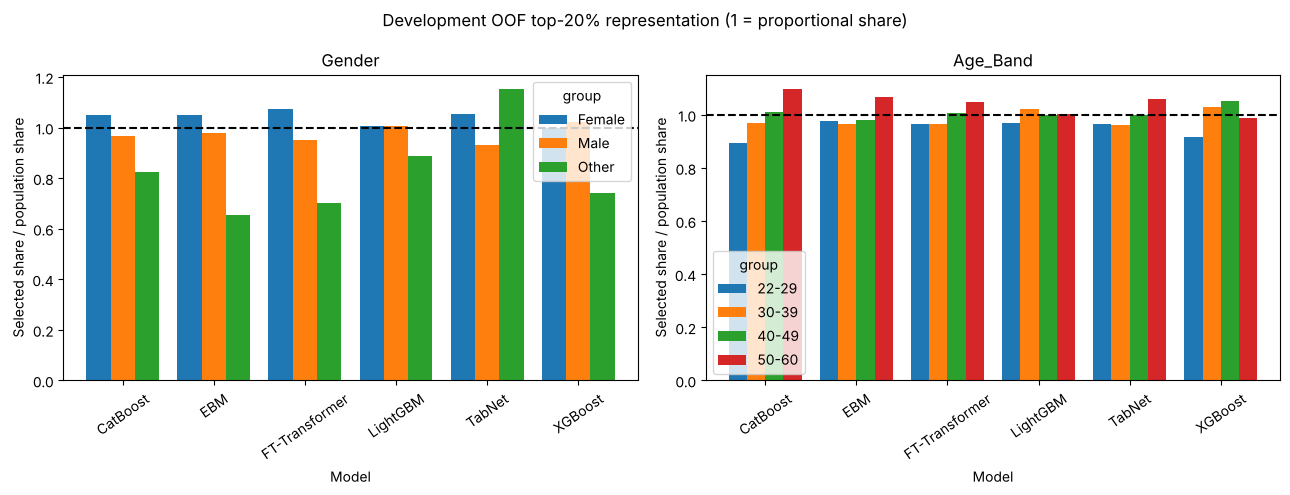

In [5]:
gap_rows = []
for (model, grouping), table in subgroups.groupby(["model", "grouping"], sort=False):
    row = {"model": model, "grouping": grouping, "groups": len(table),
           "minimum_group_rows": int(table.n.min()), "minimum_group_positives": int(table.positive_count.min())}
    for metric in ["recall", "false_positive_rate", "predicted_positive_rate"]:
        values = table[metric].dropna()
        row[metric + "_spread"] = float(values.max() - values.min()) if len(values) >= 2 else np.nan
    gap_rows.append(row)
gaps = pd.DataFrame(gap_rows)
display(gaps)

out = ROOT / "results/fairness"
out.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, grouping in zip(axes, ["Gender", "Age_Band"]):
    table = representation.loc[representation.grouping == grouping].pivot(
        index="model", columns="group", values="representation_ratio")
    if grouping == "Age_Band":
        table = table.reindex(columns=age_labels)
    table.plot.bar(ax=ax, width=.8)
    ax.axhline(1, color="black", linestyle="--")
    ax.set(title=grouping, ylabel="Selected share / population share", xlabel="Model")
    ax.tick_params(axis="x", rotation=35)
fig.suptitle("Development OOF top-20% representation (1 = proportional share)")
fig.tight_layout()
fig.savefig(out / "figure_01_top20_representation.png", dpi=160)
plt.show()
plt.close(fig)

## 5. Interpretation, mitigation and evidence limits

Small average differences can hide subgroup failures, while small denominators make rates noisy. Inspect positive and negative counts before interpreting a gap. This notebook does not estimate confidence intervals or adjust for multiple comparisons. The five OOF models have overlapping training data, so pooled subgroup diagnostics are not independent experiments.

A safe academic conclusion reports these limitations and rejects operational use given the weak predictive signal. Sensitive-feature ablations, better data provenance and independently validated probability/threshold choices would be separate development work. Model explanations describe associations and cannot establish causes of resignation or intervention effectiveness.

In [6]:
summary = {
    "age_bands": age_labels, "scope": "development OOF only", "diagnostics_complete": True,
    "development_rows": len(reference), "models": sorted(frames),
    "reference_threshold": THRESHOLD, "capacity": CAPACITY,
    "minimum_ranking_group_size": MIN_COUNT, "undefined_rate_policy": "missing, never fabricated zero",
    "formal_holdout_accessed": False, "sensitive_feature_ablations_executed": False,
    "prohibited_use": "No real hiring, firing, promotion, surveillance, disciplinary action, or automated retention decision.",
    "interpretation": "These descriptive subgroup diagnostics do not establish operational fairness; predictive discrimination remains near no-skill.",
}
display(Markdown("**Fairness diagnostics are complete; operational fairness is not established.** "
                 "Read the denominators, threshold-specific errors and fixed-capacity representation together."))

**Fairness diagnostics are complete; operational fairness is not established.** Read the denominators, threshold-specific errors and fixed-capacity representation together.

## 6. Export and completion checks

Export subgroup metrics, representation ratios, descriptive gap tables and the decision summary. These contain aggregate groups, never individual employee scores. Verify all output values by reading them back.

In [7]:
def save_verified_table(frame, path):
    """Export an aggregate table and verify its values survive the CSV round trip."""
    frame.to_csv(path, index=False)
    saved = pd.read_csv(path)
    pd.testing.assert_frame_equal(saved, frame.reset_index(drop=True), check_dtype=False,
                                  rtol=1e-10, atol=1e-12)


def save_verified_json(document, path):
    """Reject non-finite JSON values and confirm a readable, exact round trip."""
    path.write_text(json.dumps(document, indent=2, allow_nan=False), encoding="utf-8")
    assert json.loads(path.read_text(encoding="utf-8")) == document

In [8]:
save_verified_table(subgroups, out / "subgroup_metrics.csv")
save_verified_table(representation, out / "top20_representation.csv")
save_verified_table(gaps, out / "subgroup_gaps.csv")
save_verified_json(summary, out / "fairness_summary.json")
assert subgroups.groupby(["model", "grouping"]).n.sum().eq(len(reference)).all()
assert representation.groupby(["model", "grouping"]).selected_count.sum().eq(round(len(reference) * CAPACITY)).all()
print("Complete: all six models retain every development row; subgroup and allocation exports verified.")

Complete: all six models retain every development row; subgroup and allocation exports verified.
